## Setup

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## Part 1: Load and Clean



In [2]:
data = pd.read_csv("food_delivery_orders.csv")
df = data.copy()
df

,order_id,order_datetime,customer_id,customer_age,gender,area,restaurant_category,payment_method,items_count,order_value,discount_pct,delivery_fee,delivery_time,rating,order_status,device,is_member,notes
0,ORD-101393,"May 17, 2025 07:53 PM",C3133,28.0,Male,Heliopolis,Desserts,Wallet,5,215.01,10,0.0,44.0,5.0,Delivred,Android,yes,NaN
1,ORD-103813,12/12/2025 20:34,C2788,26.0,Female,New Cairo,Pizza,Credit Card,2,172.21,10,0.0,52.0,NaN,Delivred,iOS,True,NaN
2,ORD-100920,2025-06-20 22:55,C2200,36.0,Male,Heliopolis,Pizza,InstaPay,4,340.23,20,12.5,36 mins,NaN,Delivered,Android,False,NaN
3,ORD-100306,"Aug 28, 2025 08:23 PM",C1198,38.0,Male,New Cairo,Shawarma,Credit Card,3,128.79,0%,14.3,35 min,4.0,Delivered,Web,No,NaN
4,ORD-104161,07/11/2025 19:57,C2869,32.0,Male,Zamalek,Healthy,COD,3,195.33,10,0.0,39.0,NaN,Delivered,iOS,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6135,ORD-101293,"Apr 19, 2025 11:59 AM",C2271,28.0,Male,new cairo,SHAWARMA,Cash,3,EGP 199.26,0,14.3,44 min,NaN,Delivered,Web,N,NaN
6136,ORD-104023,22/11/2025 00:22,C2907,36.0,Male,Heliopolis,Pizza,Instapay,4,326.2,15,0.0,34 min,NaN,Delivered,Android,yes,NaN
6137,ORD-105200,"Aug 19, 2025 12:05 PM",C3003,26.0,Female,Nasr City,Seafood,Credit Card,1,343.45,0,13.0,42.0,NaN,Cancelled,iOS,no,NaN
6138,ORD-103775,26/09/2025 17:52,C1441,27.0,Male,Heliopolis,Koshary,Credit Card,2,76.22,0%,12.5,34.0,3.0,Delivered,iOS,No,NaN


### ℹ️ Dataset Information & Data Types

In [3]:
df.info() #informatin about data 

<class 'pandas.DataFrame'>
RangeIndex: 6140 entries, 0 to 6139
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_id             6140 non-null   str    
 1   order_datetime       6140 non-null   str    
 2   customer_id          6140 non-null   str    
 3   customer_age         5763 non-null   float64
 4   gender               5890 non-null   str    
 5   area                 6081 non-null   str    
 6   restaurant_category  6077 non-null   str    
 7   payment_method       6071 non-null   str    
 8   items_count          6140 non-null   int64  
 9   order_value          6128 non-null   str    
 10  discount_pct         6140 non-null   str    
 11  delivery_fee         5812 non-null   float64
 12  delivery_time        6111 non-null   str    
 13  rating               4776 non-null   float64
 14  order_status         6140 non-null   str    
 15  device               6005 non-null   str    
 16 

### 👯‍♂️ Handling Duplicate Records

In [4]:
#explore and drop duplicated values 
print("dublicated rows",df.duplicated().sum())
print("dublicated columns",df.T.duplicated().sum())
duplicated_data = df[df.duplicated(keep=False)]
duplicated_data
df = df.drop_duplicates()
print("The data has been removed",df.duplicated().sum())

dublicated rows 104
dublicated columns 0
The data has been removed 0


In [5]:
df.head()

,order_id,order_datetime,customer_id,customer_age,gender,area,restaurant_category,payment_method,items_count,order_value,discount_pct,delivery_fee,delivery_time,rating,order_status,device,is_member,notes
0,ORD-101393,"May 17, 2025 07:53 PM",C3133,28.0,Male,Heliopolis,Desserts,Wallet,5,215.01,10,0.0,44.0,5.0,Delivred,Android,yes,NaN
1,ORD-103813,12/12/2025 20:34,C2788,26.0,Female,New Cairo,Pizza,Credit Card,2,172.21,10,0.0,52.0,NaN,Delivred,iOS,True,NaN
2,ORD-100920,2025-06-20 22:55,C2200,36.0,Male,Heliopolis,Pizza,InstaPay,4,340.23,20,12.5,36 mins,NaN,Delivered,Android,False,NaN
3,ORD-100306,"Aug 28, 2025 08:23 PM",C1198,38.0,Male,New Cairo,Shawarma,Credit Card,3,128.79,0%,14.3,35 min,4.0,Delivered,Web,No,NaN
4,ORD-104161,07/11/2025 19:57,C2869,32.0,Male,Zamalek,Healthy,COD,3,195.33,10,0.0,39.0,NaN,Delivered,iOS,True,NaN


### 🗓️ Cleaning Datetime & Extracting Features (Year, Month, Day)

In [6]:
#convert order_datetime from str to datetime
df["order_datetime"] = pd.to_datetime(df["order_datetime"], errors='coerce') 
print("missing values " , df["order_datetime"].isna().sum()) #missing time values 
print("data type is " , df["order_datetime"].dtypes ) #data type for order_datetime after covert 

#new columns 
df["month"] = df["order_datetime"].dt.month
df["year"] = df["order_datetime"].dt.year
df["day"] = df["order_datetime"].dt.day_name()

#convert datatypes from float to int 
df["month"] = df["month"].astype("Int64")
df["year"] =df["year"].astype("Int64")
df.head()

C:\Users\tefa_\AppData\Local\Temp\ipykernel_5812\2430725028.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["order_datetime"] = pd.to_datetime(df["order_datetime"], errors='coerce')


missing values  26
data type is  datetime64[us]


,order_id,order_datetime,customer_id,customer_age,gender,area,restaurant_category,payment_method,items_count,order_value,discount_pct,delivery_fee,delivery_time,rating,order_status,device,is_member,notes,month,year,day
0,ORD-101393,2025-05-17 19:53:00,C3133,28.0,Male,Heliopolis,Desserts,Wallet,5,215.01,10,0.0,44.0,5.0,Delivred,Android,yes,NaN,5,2025,Saturday
1,ORD-103813,2025-12-12 20:34:00,C2788,26.0,Female,New Cairo,Pizza,Credit Card,2,172.21,10,0.0,52.0,NaN,Delivred,iOS,True,NaN,12,2025,Friday
2,ORD-100920,2025-06-20 22:55:00,C2200,36.0,Male,Heliopolis,Pizza,InstaPay,4,340.23,20,12.5,36 mins,NaN,Delivered,Android,False,NaN,6,2025,Friday
3,ORD-100306,2025-08-28 20:23:00,C1198,38.0,Male,New Cairo,Shawarma,Credit Card,3,128.79,0%,14.3,35 min,4.0,Delivered,Web,No,NaN,8,2025,Thursday
4,ORD-104161,2025-07-11 19:57:00,C2869,32.0,Male,Zamalek,Healthy,COD,3,195.33,10,0.0,39.0,NaN,Delivered,iOS,True,NaN,7,2025,Friday


In [7]:
df["customer_id"].nunique() #unique values of customer id 

2063

### 🎂 Cleaning Customer Age & Outliers

In [8]:
df["customer_age"].value_counts()
# replace outlaiers values by mean 
df["customer_age"] = df["customer_age"].replace([-1, 0,999,5, 120], np.nan)
df["customer_age"] = df["customer_age"].fillna(df["customer_age"].mean()).round().astype("Int64")# convert customer_age from float to int 

In [9]:
df["gender"].value_counts() #values of gender 

gender
Male      3226
Female    2566
Name: count, dtype: int64

### 📍 Standardizing Area Names

In [10]:
df["area"] = df["area"].str.strip().str.title() # remove sapce 
df["area"].value_counts() #values of area

area
New Cairo          1211
Nasr City           963
Heliopolis          746
Maadi               744
Sheikh Zayed        667
6Th October         564
Zamalek             449
Dokki               444
New  Cairo           79
Nasr City.           56
6 October            29
El Sheikh Zayed      26
Name: count, dtype: int64

In [11]:
#Handle area 
df["area"] = df["area"].replace({
    "New  Cairo": "New Cairo",
    "Nasr City.": "Nasr City",
    "El Sheikh Zayed": "Sheikh Zayed",
    "6 October": "6Th October" ,
    "6th October" : "6Th October"
}) 
df["area"].value_counts() #values of area

area
New Cairo       1290
Nasr City       1019
Heliopolis       746
Maadi            744
Sheikh Zayed     693
6Th October      593
Zamalek          449
Dokki            444
Name: count, dtype: int64

### 🍽️ Standardizing Restaurant Categories

In [12]:
df["restaurant_category"] = df["restaurant_category"].str.strip().str.title() # remove sapce 
df["restaurant_category"] = df["restaurant_category"].replace({
    "Shawarma": "Shawerma",
    "Koshari": "Koshary",
    "Healthy Food": "Healthy",
    "Sweets": "Desserts"
}) 
df["restaurant_category"].value_counts() #values of restaurant_category

restaurant_category
Burgers     1124
Pizza        922
Shawerma     872
Koshary      825
Grills       725
Healthy      520
Desserts     511
Seafood      475
Name: count, dtype: int64

### 💳 Standardizing Payment Methods

In [13]:
df["payment_method"] = df["payment_method"].str.strip().str.title() # remove sapce 
# handle columns 
df["payment_method"] = df["payment_method"].replace({
    "Cod": "Cash On Delivery",
    "Cc": "Credit Card",
    "Visa": "Credit Card",
    "E-Wallet": "Wallet",
    "Vodafone Cash": "Wallet"
})
df["payment_method"].value_counts()


payment_method
Cash                1855
Credit Card         1844
Wallet              1112
Instapay             710
Cash On Delivery     446
Name: count, dtype: int64

### 🧹 Cleaning Items Count & Removing Invalid Values

In [14]:
df.drop(df[df["items_count"] <= 0].index, inplace=True)
df["items_count"].value_counts()

items_count
3     1584
2     1377
4     1235
5      702
1      608
6      334
7      113
8       49
40       7
99       7
9        6
10       2
Name: count, dtype: int64

### 💰 Cleaning Order Value & Removing Outliers

In [15]:
df["order_value"] = df["order_value"].str.strip().str.title() # remove sapce 
df["order_value"] = df["order_value"].str.replace("Egp", "", regex=False).str.strip() #remove egp 
# handle data 
df["order_value"] = df["order_value"].replace({ 
    "Free" : "0" ,
    "-": np.nan,
    "Unknown": np.nan
})
df["order_value"] = df["order_value"].str.replace(",", "", regex=False) # remove "," becouse convert to float 
df["order_value"] = df["order_value"].astype(float)


In [16]:
df = df[~df["order_value"].isin([99999.00, 48000.00, 50000.0,25000.00])]  # remove outlier 
# rename column 
df = df.rename(columns={"order_value": "order_amount"}) 

### 🏷️ Formatting Discount Percentages

In [17]:
#remove "%" from column 
df["discount_pct"] = df["discount_pct"].astype(str).str.replace("%", "", regex=False).str.strip()
#convert datatype to float
df["discount_pct"] = df["discount_pct"].astype(float)
# handle colmun
df["discount_pct"] = df["discount_pct"].replace({
    10: 0.10,
    15: 0.15,
    20: 0.20,
    25: 0.25,
    5: 0.05
})

### ⏱️ Cleaning Delivery Time & Imputing Missing Values

In [18]:
#handle column
df["delivery_time"] = df["delivery_time"].str.replace(" mins", "", regex=False).str.replace(" min", "", regex=False)
df["delivery_time"] = df["delivery_time"].replace(["-", "unknown"], np.nan) 
df["delivery_time"] = df["delivery_time"].astype(float)
df["delivery_time"].dtypes #cheak datatype 
df["delivery_time"] = df["delivery_time"].fillna(df["delivery_time"].mean()).round(2) 

### ⭐ Fixing Rating Outliers

In [19]:
df.loc[df["rating"] > 5, "rating"] = 5 #convert any num >5 to 5 
df["rating"].value_counts()

rating
4.0    2456
5.0    1094
3.0    1021
2.0      90
0.0      12
1.0       1
Name: count, dtype: int64

### 📱 Standardizing Device Types

In [20]:
df["device"] = df["device"].str.strip().str.title() # remove sapce 
# handle column
df["device"] = df["device"].replace({
    "Android Os": "Android",
    "Website": "Web",
    "Ios": "iOS"
})
df["device"].value_counts()

device
Android    3066
iOS        2222
Web         591
Name: count, dtype: int64

### 📦 Standardizing Order Status

In [21]:
df["order_status"] = df["order_status"].str.strip().str.title() # remove sapce 
# handle column
df["order_status"] = df["order_status"].replace({
    "Delivred": "Delivered",
    "Canceled": "Cancelled",
    "Refund": "Refunded"
})
df["order_status"].value_counts()

order_status
Delivered    5536
Cancelled     300
Refunded      174
Name: count, dtype: int64

### 👑 Standardizing Membership Status

In [22]:
# handle column
df["is_member"] = df["is_member"].replace({
    "N": "No",
    "0": "No",
    "False": "No",
    "no": "No",
    "Y": "Yes",
    "1": "Yes",
    "True": "Yes",
    "yes": "Yes"
})
df["is_member"].value_counts()

is_member
No     3886
Yes    2124
Name: count, dtype: int64

### 🗑️ Dropping Unnecessary Columns (`notes`)

In [23]:
df.drop(columns=["notes"], inplace=True)
df.head()

,order_id,order_datetime,customer_id,customer_age,gender,area,restaurant_category,payment_method,items_count,order_amount,discount_pct,delivery_fee,delivery_time,rating,order_status,device,is_member,month,year,day
0,ORD-101393,2025-05-17 19:53:00,C3133,28,Male,Heliopolis,Desserts,Wallet,5,215.01,0.1,0.0,44.0,5.0,Delivered,Android,Yes,5,2025,Saturday
1,ORD-103813,2025-12-12 20:34:00,C2788,26,Female,New Cairo,Pizza,Credit Card,2,172.21,0.1,0.0,52.0,NaN,Delivered,iOS,Yes,12,2025,Friday
2,ORD-100920,2025-06-20 22:55:00,C2200,36,Male,Heliopolis,Pizza,Instapay,4,340.23,0.2,12.5,36.0,NaN,Delivered,Android,No,6,2025,Friday
3,ORD-100306,2025-08-28 20:23:00,C1198,38,Male,New Cairo,Shawerma,Credit Card,3,128.79,0.0,14.3,35.0,4.0,Delivered,Web,No,8,2025,Thursday
4,ORD-104161,2025-07-11 19:57:00,C2869,32,Male,Zamalek,Healthy,Cash On Delivery,3,195.33,0.1,0.0,39.0,NaN,Delivered,iOS,Yes,7,2025,Friday


### **Question 1.** How did the number of orders change month by month across 2025? 

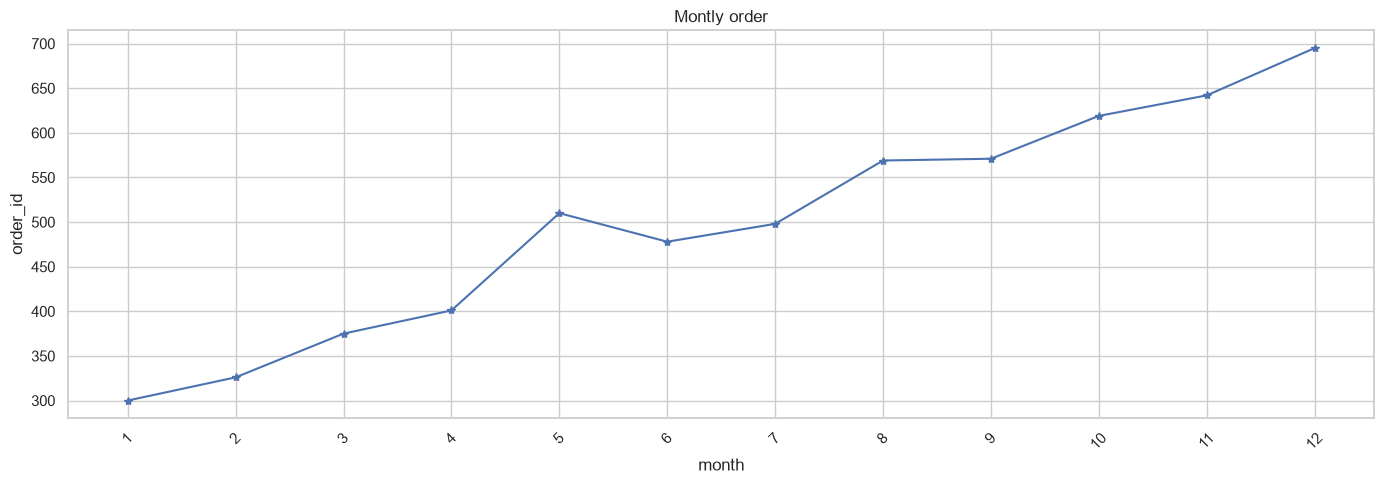

In [24]:
total_orders = (df.groupby("month" , as_index = False )["order_id"].count())
plt.figure(figsize=(14,5))
plt.plot(
    total_orders["month"] ,
    total_orders["order_id"],
    marker = "*"
)
plt.title("Montly order")
plt.xlabel("month")
plt.ylabel("order_id")
plt.xticks(range(1, 13),rotation = 45)
plt.tight_layout()
plt.show()
#orders increased from 9th month to 12th month 

### **Question 2.** Which restaurant categories bring the most revenue? 

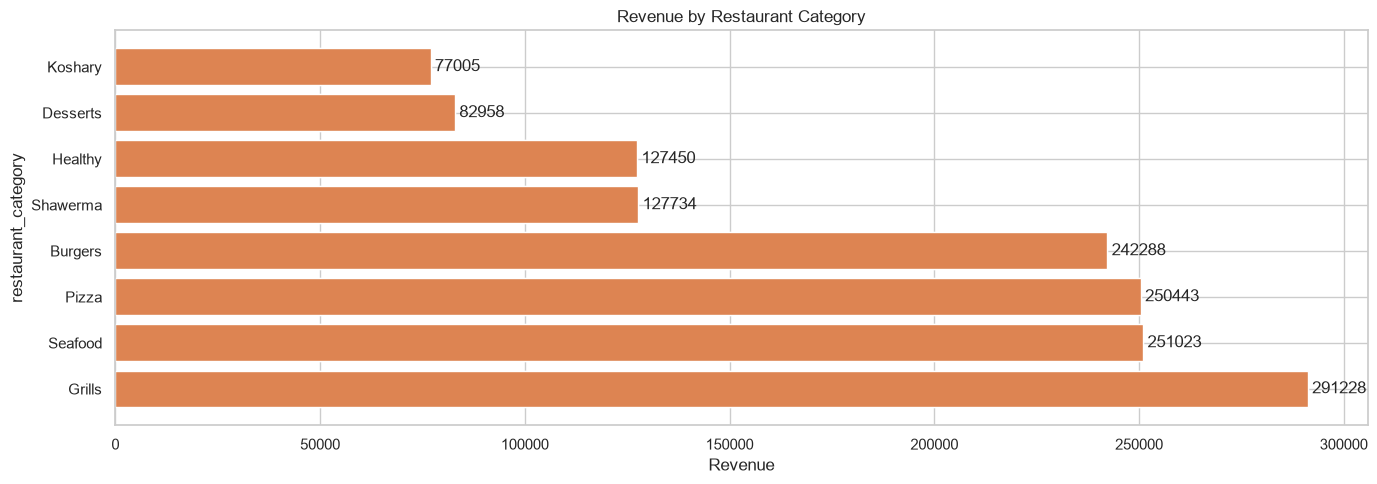

In [25]:
#calculate Revenue
delivered = df[df["order_status"] == "Delivered"]
most_revenue = (delivered.groupby("restaurant_category", as_index=False)["order_amount"].sum().sort_values("order_amount", ascending=False))
plt.figure(figsize=(14,5))
plt.barh(most_revenue["restaurant_category"],most_revenue["order_amount"])
bars = plt.barh(
    most_revenue["restaurant_category"], most_revenue["order_amount"]
)
plt.title("Revenue by Restaurant Category")
plt.xlabel("Revenue")
plt.ylabel("restaurant_category")
plt.xticks(rotation = 0 )
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()
#category grills the most profit 

### **Question 3.** How is order value distributed?

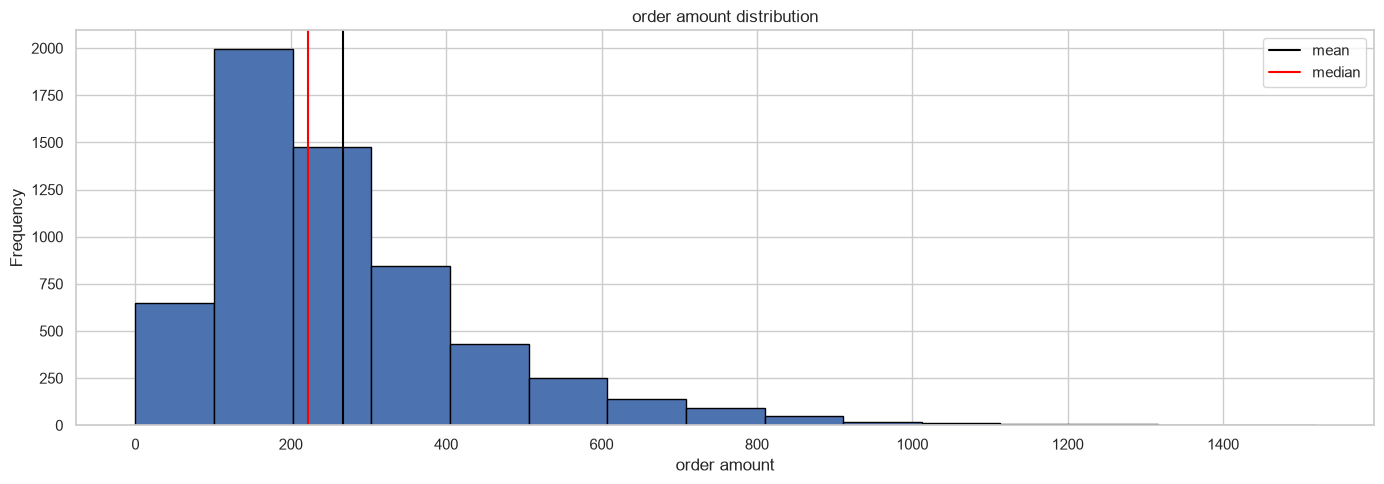

In [26]:
mean = df["order_amount"].mean()
median = df["order_amount"].median()
plt.figure(figsize=(14,5))
plt.hist(
    df["order_amount"] ,
    bins = 15 ,
    edgecolor = "black"
)
plt.axvline(mean, color = "black" , label = "mean")
plt.axvline(median, color="red", label="median")
plt.legend()
plt.title("order amount distribution")
plt.xlabel("order amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
#the most orders between 100 to 300 

### **Question 4.** What share of orders does each payment method hold? 

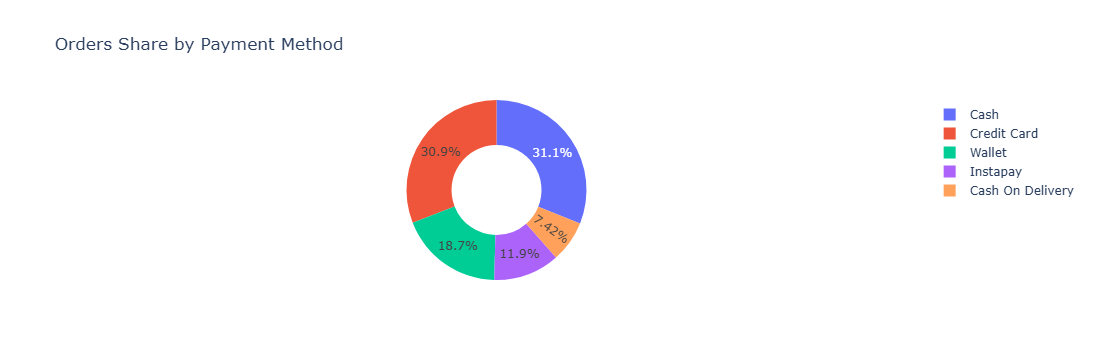

In [27]:
payment = df.groupby("payment_method")["order_status"].count().reset_index()
fig = px.pie(
    payment,
    names="payment_method",
    values="order_status",
    hole=0.5,
    title="Orders Share by Payment Method"
    )
fig.show()
#the most payment : cash 

### **Question 5.** Is slower delivery linked to lower ratings?

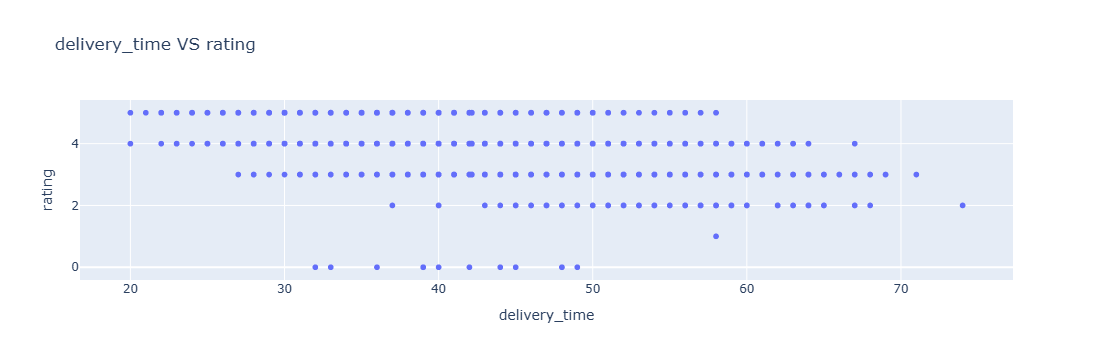

In [28]:
delivered_orders = df[(df["order_status"] == "Delivered") &(df["delivery_time"].notna()) &(df["rating"].notna())]
fig = px.scatter(
    delivered_orders, 
    x = "delivery_time" ,
    y = "rating" ,
    title = "delivery_time VS rating "
)
fig.show()

### **Question 6.** Which day of the week has the highest average order value?

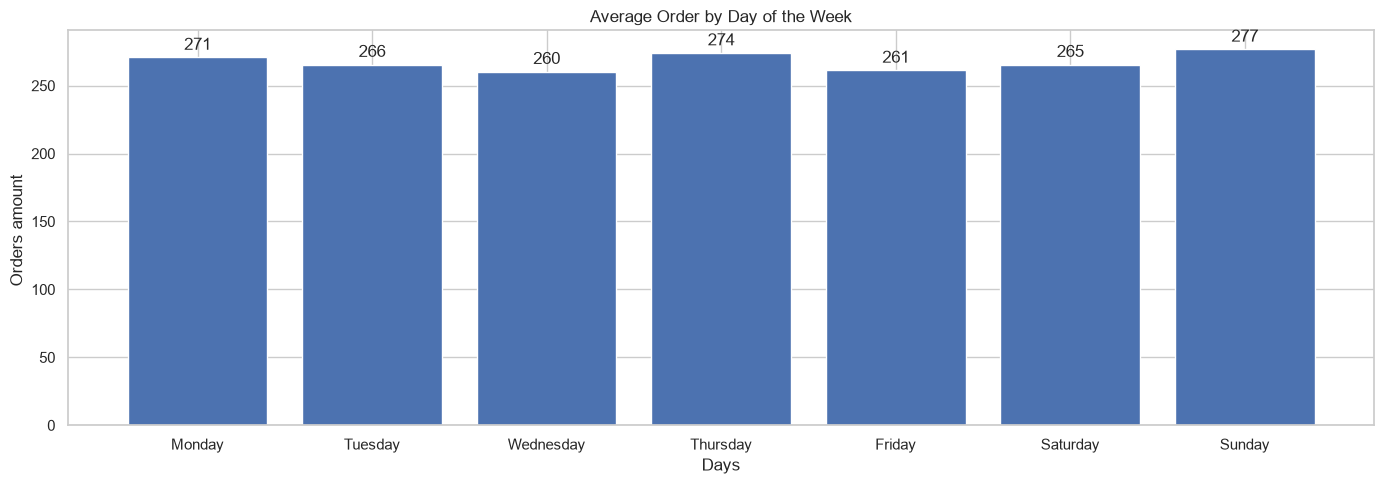

In [29]:
day_mean = df.groupby("day", as_index=False)["order_amount"].mean()
days = {
    "Monday": 1,
    "Tuesday": 2,
    "Wednesday": 3,
    "Thursday": 4,
    "Friday": 5,
    "Saturday": 6,
    "Sunday": 7
}
day_mean["order"] = day_mean["day"].map(days)
day_mean = day_mean.sort_values("order")

plt.figure(figsize=(14,5))
barss = plt.bar(
    day_mean["day"] ,
    day_mean["order_amount"]
)
plt.title("Average Order by Day of the Week")
plt.xlabel("Days")
plt.ylabel("Orders amount ")
plt.xticks(rotation = 0 )
plt.bar_label(barss, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()
#sunday the heights

### **Question 7.** Which areas have the slowest deliveries, and how much do they vary? 

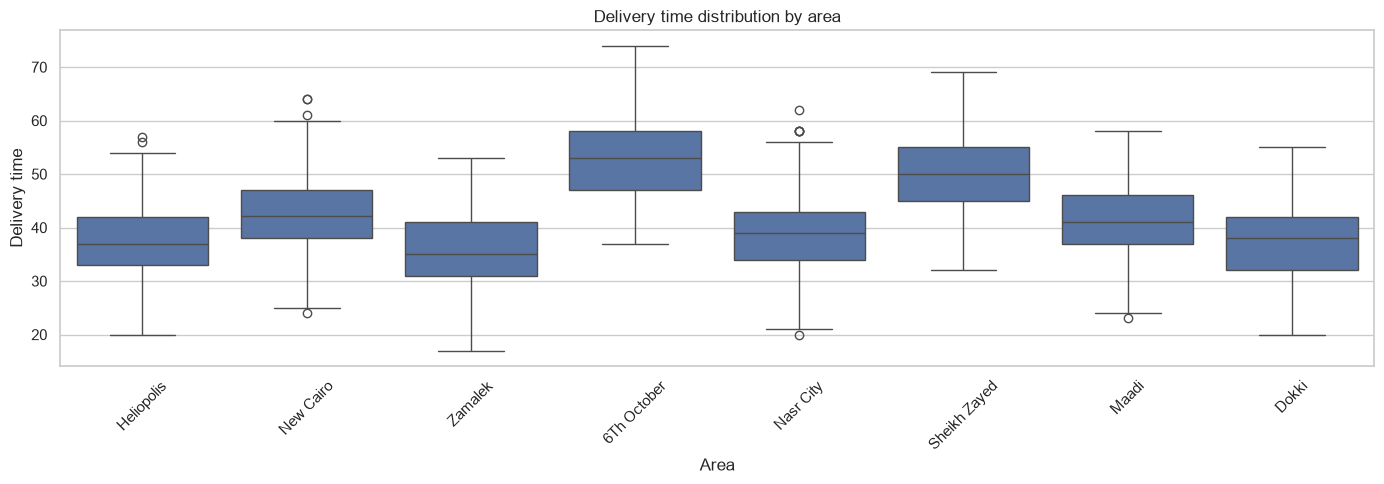

In [30]:
plt.figure(figsize=(14, 5))
sns.boxplot(
    data=df,
    x="area",
    y="delivery_time"
)
plt.title("Delivery time distribution by area")
plt.xlabel("Area")
plt.ylabel("Delivery time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
#6Th october the slowest ordered , however zamalek the faster ordered 

### **Question 8.** How do order outcomes (Delivered, Cancelled, Refunded) differ across restaurant categories?

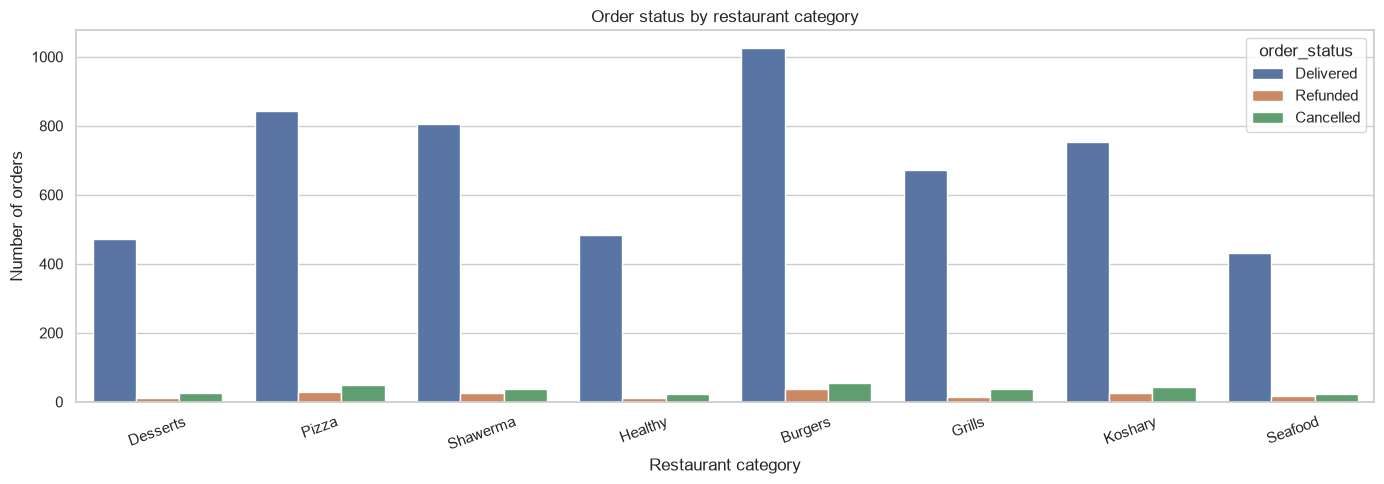

In [31]:
plt.figure(figsize=(14, 5))
sns.countplot(
    data=df,
    x="restaurant_category",
    hue="order_status"
)
plt.title("Order status by restaurant category")
plt.xlabel("Restaurant category")
plt.ylabel("Number of orders")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
#burgers the most deliverd ,  burgers the most cancelled , and burgers the most refunded 

### **Question 9.** Which numeric columns are related to each other?

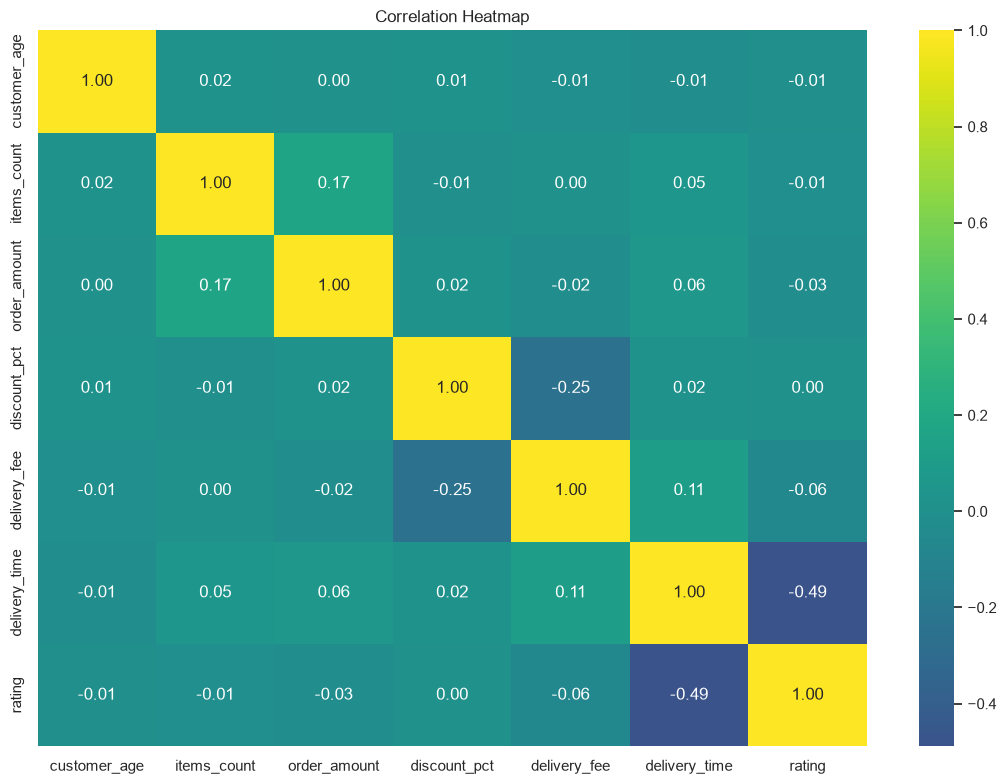

In [32]:
numeric_cols = [
    "customer_age",
    "items_count",
    "order_amount",
    "discount_pct",
    "delivery_fee",
    "delivery_time",
    "rating",
]
corr = df[numeric_cols].corr()
corr

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
#There is a strong Negtive correlation between rating and delivery time , 
#and There is a strong positive correlation between order_amount and items_count.

### **Question 10.** How does order value vary within each restaurant category? Plot a violin plot.

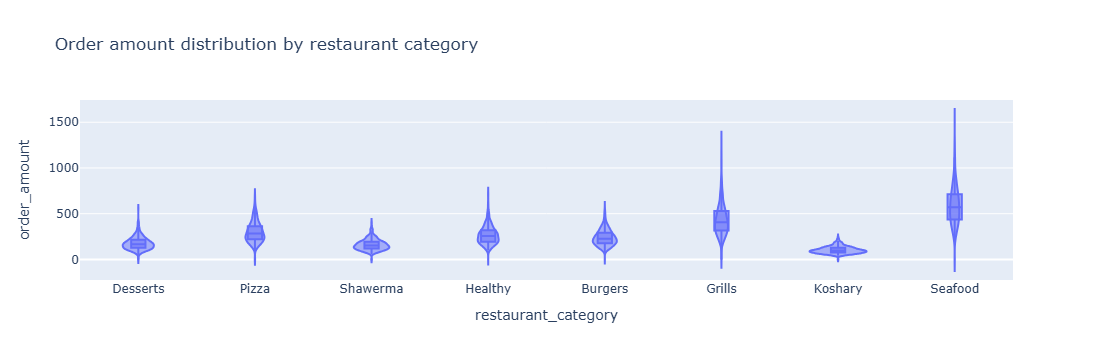

In [33]:
# TODO
fig = px.violin(
    df,
    x="restaurant_category",
    y="order_amount",
    box=True,
    points=False,
    title="Order amount distribution by restaurant category"
)

fig.show()

### **Question 11.** How are customer ages distributed for each gender?

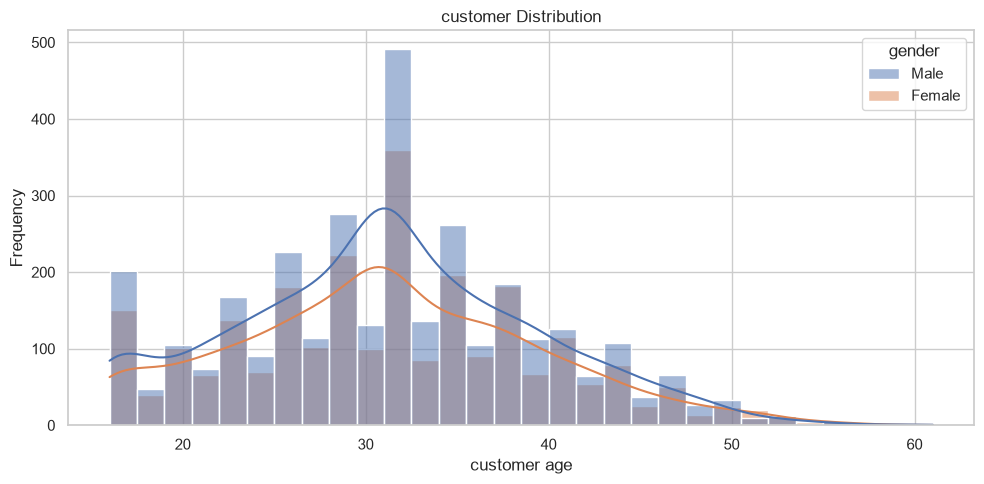

In [34]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="customer_age",
    hue="gender",
    bins=30,
    kde=True
)

plt.title("customer Distribution")
plt.xlabel("customer age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### **Question 12.** When are the busiest times of the week?

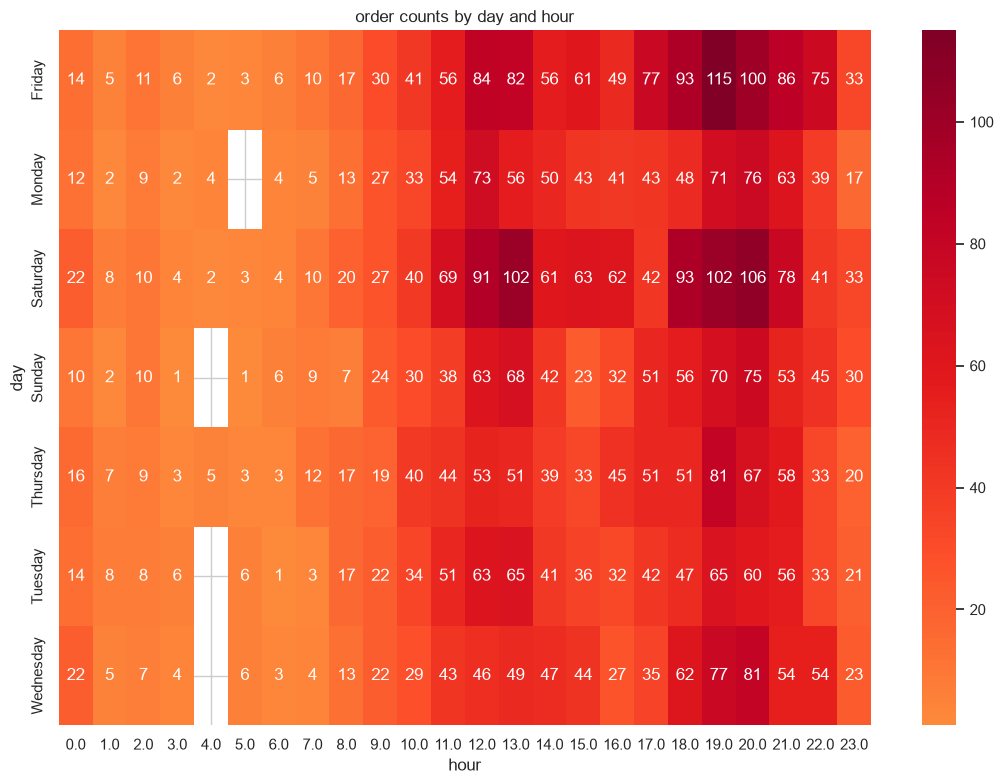

In [35]:
df["hour"] = df["order_datetime"].dt.hour 
pivot = df.pivot_table(
    index="day",
    columns="hour",
    values="order_id",
    aggfunc="count"
)
plt.figure(figsize=(11, 8))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    center=0
)

plt.title("order counts by day and hour")
plt.tight_layout()
plt.show()

### **Question 13.** How do order value, delivery time, rating and items count relate to each other?

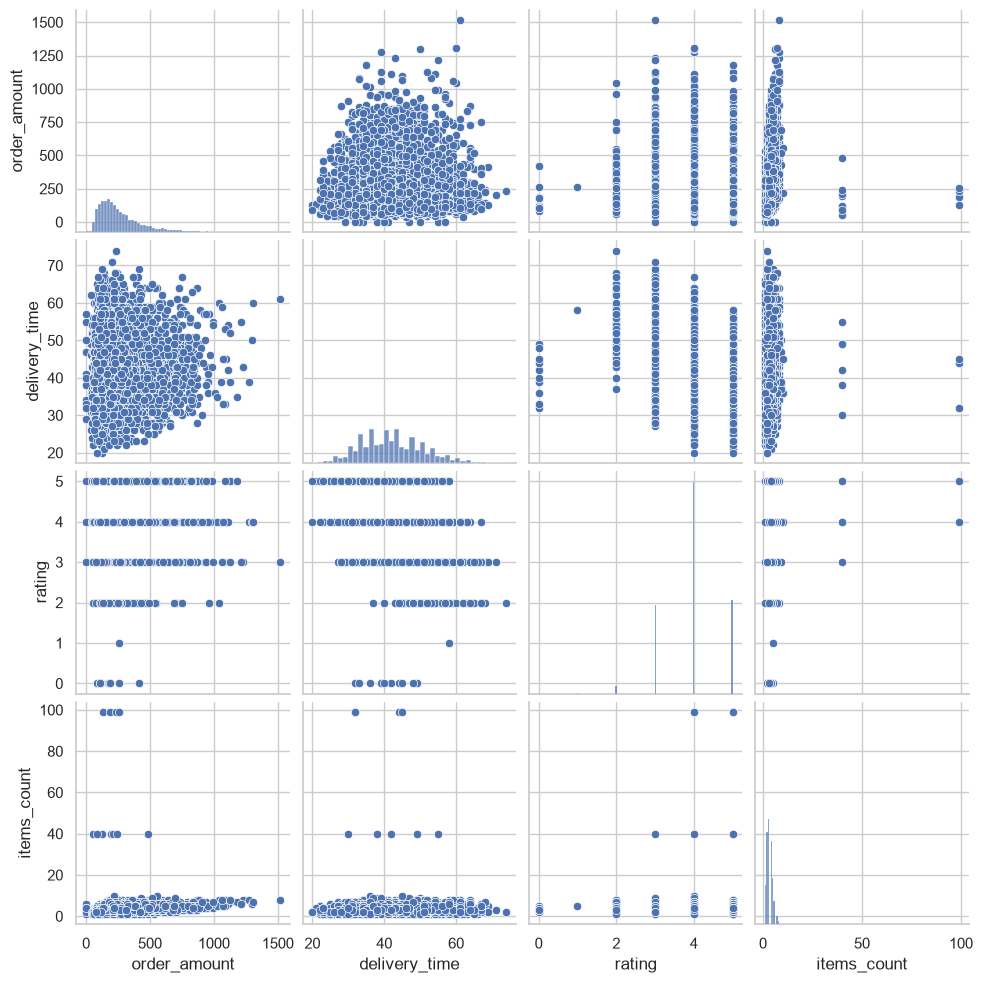

In [36]:
pair_cols = [
    "order_amount",
    "delivery_time",
    "rating",
    "items_count"
]
sns.pairplot(
    df[pair_cols].dropna(),
    diag_kind="hist"
)
plt.show()

### **Question 14.** How did monthly revenue evolve for each payment method?

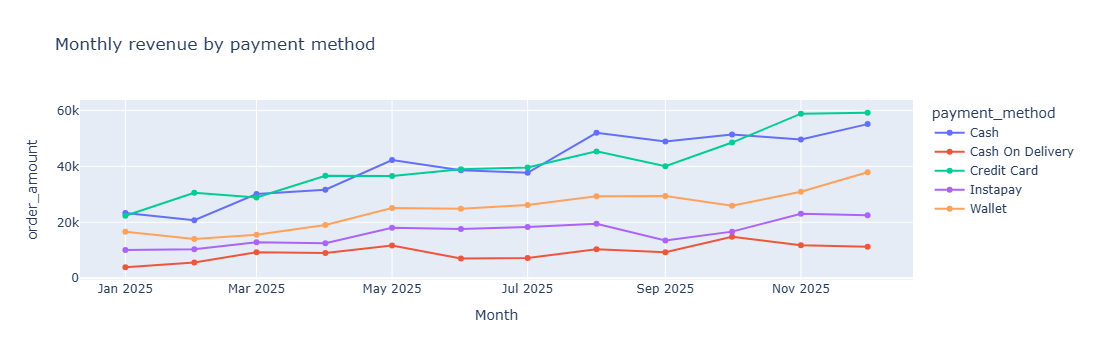

In [37]:
monthly_payment = (
    df.assign(Month=df["order_datetime"].dt.to_period("M").astype(str))
      .groupby(["Month", "payment_method"], as_index=False)["order_amount"]
      .sum()
)

fig = px.line(
    monthly_payment,
    x="Month",
    y="order_amount",
    color="payment_method",
    markers=True,
    title="Monthly revenue by payment method"
)

fig.show()

### **Question 15.** Where does revenue come from, by area and category? 

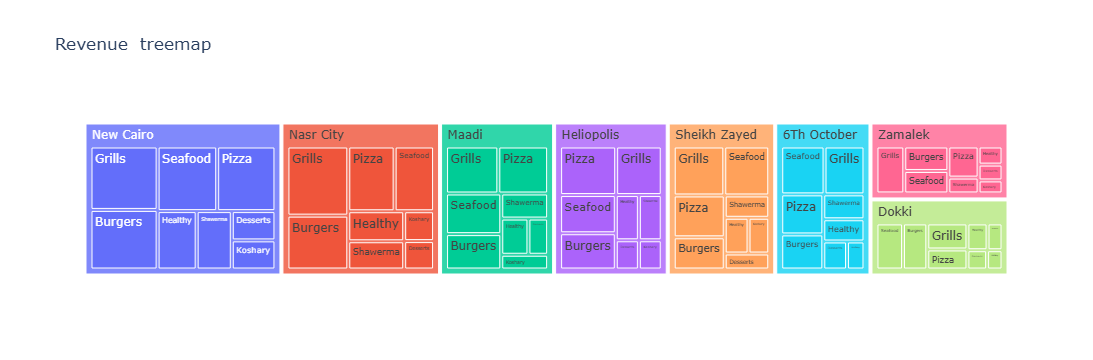

In [38]:
treemap_data = (
    df.groupby(["area", "restaurant_category"], as_index=False)["order_amount"]
      .sum()
)

fig = px.treemap(
    treemap_data,
    path=["area", "restaurant_category"],
    values="order_amount",
    title="Revenue  treemap"
)

fig.show()

### **Question 16.** How many orders survive from placement to a rating?

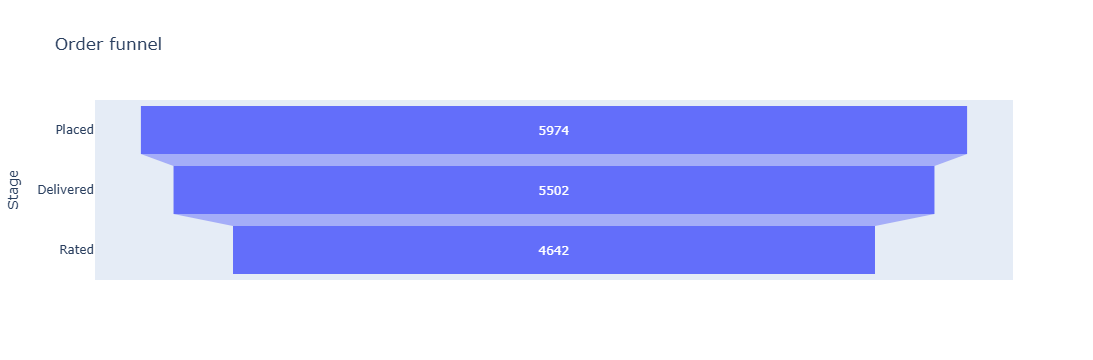

In [39]:
funnel_data = pd.DataFrame({
    "Stage": ["Placed", "Delivered", "Rated"],
    "Orders": [
        df["order_id"].nunique(),
        df[df["order_status"] == "Delivered"]["order_id"].nunique(),
        df[df["rating"].notna()]["order_id"].nunique()
    ]
})

fig = px.funnel(
    funnel_data,
    y="Stage",
    x="Orders",
    title="Order funnel"
)

fig.show()

### **Question 17.** Do bigger orders take longer to deliver?

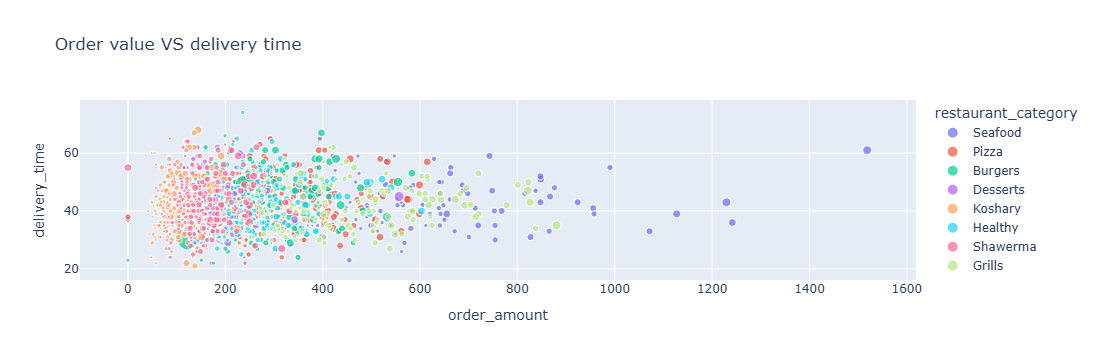

In [40]:
bubble_data = (
    df.sample(1500)
)

fig = px.scatter(
    bubble_data,
    x="order_amount",
    y="delivery_time",
    size="items_count",
    color="restaurant_category",
    hover_name="area",
    title="Order value VS delivery time"
)

fig.show()

### **Question 18.** Which area and device combinations get the best ratings? 

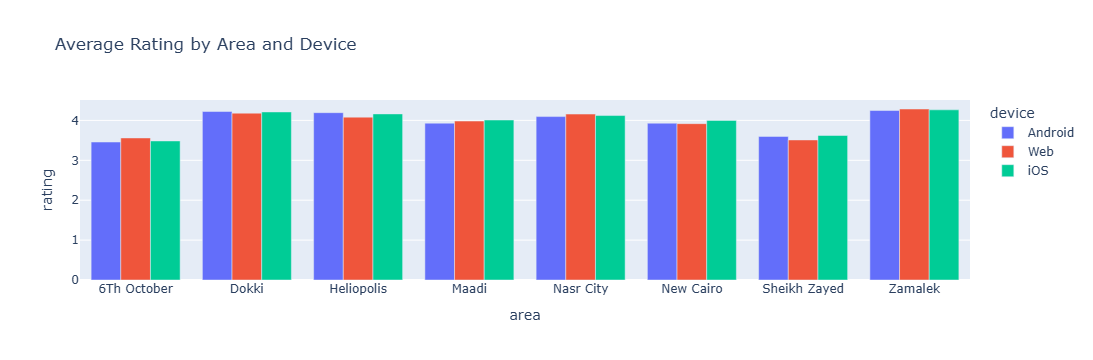

In [41]:
rating_area = (
    df.groupby(["area", "device"], as_index=False)["rating"]
      .mean()
)

fig = px.bar(
    rating_area,
    x="area",
    y="rating",
    color="device",
    barmode="group",
    title="Average Rating by Area and Device"
)

fig.show()

### **Question 19.** How do payment methods split across order statuses?

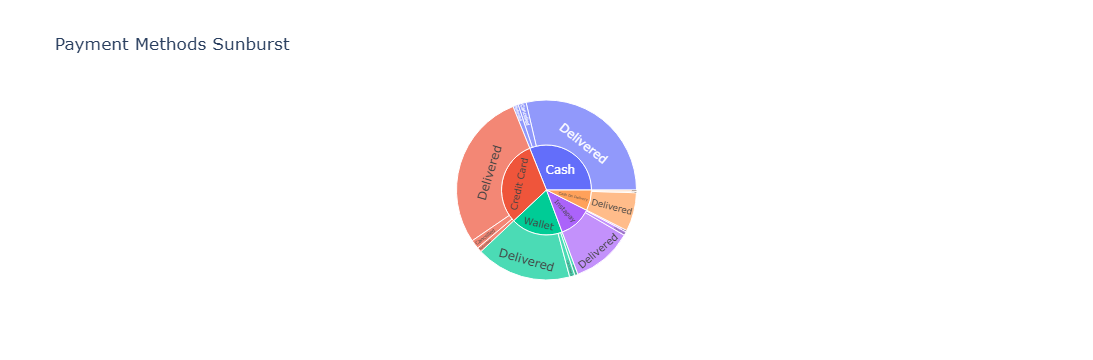

In [42]:
sunburst_data = (
    df.groupby(["payment_method", "order_status"], as_index=False)["order_id"]
      .count()
)
fig = px.sunburst(
    sunburst_data,
    path=["payment_method", "order_status"],
    values="order_id",
    title="Payment Methods Sunburst"
)

fig.show()

### **Question 20.** How did cumulative revenue build up over the year for each category?

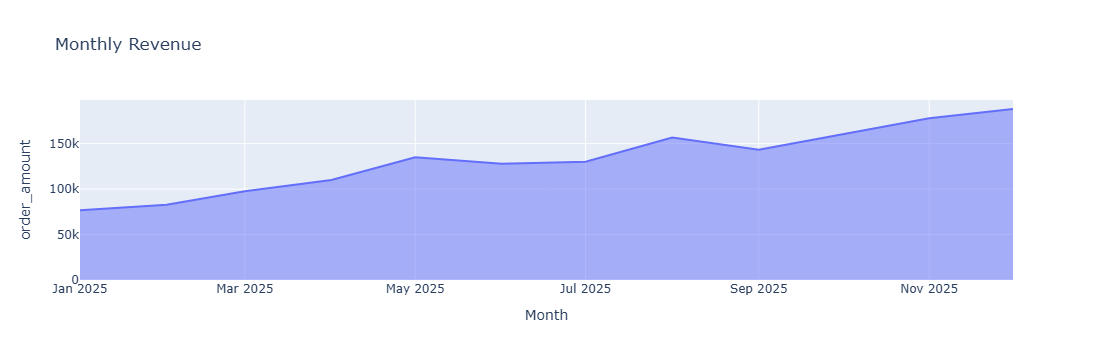

In [43]:
monthly_sales = (
    df.assign(Month=df["order_datetime"].dt.to_period("M").astype(str))
      .groupby("Month", as_index=False)["order_amount"]
      .sum()
)

fig = px.area(
    monthly_sales,
    x="Month",
    y="order_amount",
    title="Monthly Revenue"
)

fig.show()